# Machine Learning Part

In [ ]:

%pip -q install pandas requests matplotlib


In [ ]:

import requests
import pandas as pd
import time
from IPython.display import display

# Official MTA Open Data API
API_URL = "https://data.ny.gov/resource/gxb3-akrn.json"

# Start with a fixed historical week for reproducibility.
START_DATE = "2026-09-01T00:00:00"
END_DATE   = "2026-09-08T00:00:00"

params = {
    "$select": (
        "transit_timestamp, bus_route, "
        "sum(ridership) as ridership"
    ),
    "$where": (
        f"transit_timestamp >= '{START_DATE}' "
        f"AND transit_timestamp < '{END_DATE}'"
    ),
    "$group": "transit_timestamp, bus_route",
    "$order": "transit_timestamp, bus_route",
    "$limit": 50000,
}

# Fetch results in pages in case the query exceeds one page.
all_rows = []
offset = 0

while True:
    params["$offset"] = offset

    response = requests.get(
        API_URL,
        params=params,
        timeout=120
    )

    response.raise_for_status()
    batch = response.json()

    if not batch:
        break

    all_rows.extend(batch)
    print(f"Retrieved {len(all_rows):,} aggregated rows")

    if len(batch) < params["$limit"]:
        break

    offset += params["$limit"]
    time.sleep(0.2)

if not all_rows:
    raise RuntimeError(
        "No records returned. Check the date range, "
        "API availability, and dataset schema."
    )

df = pd.DataFrame(all_rows)

print("\nDownload completed.")
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head(10))


Retrieved 50,000 aggregated rows
Retrieved 75,600 aggregated rows

Download completed.
Rows: 75600
Columns: ['transit_timestamp', 'bus_route', 'ridership']


,transit_timestamp,bus_route,ridership
0,2026-09-01T00:00:00.000,B1,15
1,2026-09-01T00:00:00.000,B100,1
2,2026-09-01T00:00:00.000,B101,0
3,2026-09-01T00:00:00.000,B102,0
4,2026-09-01T00:00:00.000,B103,31
5,2026-09-01T00:00:00.000,B106,0
6,2026-09-01T00:00:00.000,B11,20
7,2026-09-01T00:00:00.000,B111,0
8,2026-09-01T00:00:00.000,B116,0
9,2026-09-01T00:00:00.000,B12,18


In [ ]:

# Work on a copy so the original API result remains available.
df = df.copy()

required_columns = {
    "transit_timestamp",
    "bus_route",
    "ridership"
}

# 1. Schema validation
missing_columns = required_columns - set(df.columns)
assert not missing_columns, (
    f"Missing expected columns: {missing_columns}"
)

# 2. Convert data types
df["transit_timestamp"] = pd.to_datetime(
    df["transit_timestamp"],
    errors="coerce"
)

df["bus_route"] = df["bus_route"].astype("string")

df["ridership"] = pd.to_numeric(
    df["ridership"],
    errors="coerce"
)

# 3. Inspect missing values
print("Missing values before cleaning:")
display(df.isna().sum().to_frame("missing_count"))

# Remove rows missing essential fields.
df = df.dropna(
    subset=["transit_timestamp", "bus_route", "ridership"]
).copy()

# 4. Validate passenger counts
negative_counts = int((df["ridership"] < 0).sum())

print("Negative ridership records:", negative_counts)

if negative_counts:
    raise ValueError(
        "Negative passenger counts found. Investigate the "
        "source data before proceeding."
    )

# 5. Check duplicate route-hour observations
duplicate_count = int(
    df.duplicated(
        subset=["transit_timestamp", "bus_route"]
    ).sum()
)

print("Duplicate route-hour records:", duplicate_count)

if duplicate_count:
    raise ValueError(
        "Duplicate route-hour rows found. Investigate before "
        "training; do not silently remove them."
    )

# 6. Check date coverage and target statistics
print("\nValidated dataset summary")
print("-------------------------")
print("Rows:", f"{len(df):,}")
print("Unique routes:", df["bus_route"].nunique())
print("Start timestamp:", df["transit_timestamp"].min())
print("End timestamp:", df["transit_timestamp"].max())
print("Unique timestamps:", df["transit_timestamp"].nunique())
print("Missing values remaining:", int(df.isna().sum().sum()))
print("Minimum ridership:", df["ridership"].min())
print("Median ridership:", df["ridership"].median())
print("Maximum ridership:", df["ridership"].max())

display(df.describe(include="all").T)


Missing values before cleaning:


,missing_count
transit_timestamp,0
bus_route,0
ridership,0


Negative ridership records: 0
Duplicate route-hour records: 0

Validated dataset summary
-------------------------
Rows: 75,600
Unique routes: 450
Start timestamp: 2026-09-01 00:00:00
End timestamp: 2026-09-07 23:00:00
Unique timestamps: 168
Missing values remaining: 0
Minimum ridership: 0
Median ridership: 16.0
Maximum ridership: 2993


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
transit_timestamp,75600,NaN,NaN,NaN,2026-09-04 11:30:00,2026-09-01 00:00:00,2026-09-02 17:45:00,2026-09-04 11:30:00,2026-09-06 05:15:00,2026-09-07 23:00:00,NaN
bus_route,75600,450,B101,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ridership,75600.0,NaN,NaN,NaN,88.747302,0.0,0.0,16.0,112.0,2993.0,157.863925


In [ ]:

# Summarise coverage by route.
route_summary = (
    df.groupby("bus_route")
      .agg(
          observations=("ridership", "size"),
          total_boardings=("ridership", "sum"),
          average_boardings=("ridership", "mean"),
          peak_hour_boardings=("ridership", "max")
      )
      .sort_values("total_boardings", ascending=False)
)

print("Top 10 routes by total boardings:")
display(route_summary.head(10).round(2))

# Aggregate passenger demand across routes by hour.
hourly_summary = (
    df.groupby("transit_timestamp", as_index=False)["ridership"]
      .sum()
      .sort_values("transit_timestamp")
)

print("First 10 hourly network totals:")
display(hourly_summary.head(10))

# Check whether route-hour combinations are missing.
expected_hours = pd.date_range(
    start=START_DATE,
    end=pd.Timestamp(END_DATE) - pd.Timedelta(hours=1),
    freq="h"
)

expected_combinations = (
    len(expected_hours) * df["bus_route"].nunique()
)

observed_combinations = len(df)

print("\nCoverage diagnostics")
print("Expected hours:", len(expected_hours))
print("Routes:", df["bus_route"].nunique())
print("Expected route-hour combinations if every route "
      "appeared every hour:", f"{expected_combinations:,}")
print("Observed route-hour combinations:", f"{observed_combinations:,}")
print("Coverage ratio under this assumption:",
      round(observed_combinations / expected_combinations, 4))


Top 10 routes by total boardings:


,observations,total_boardings,average_boardings,peak_hour_boardings
bus_route,,,,
M15+,168,135257,805.10,2993
Q44+,168,98068,583.74,1480
Q25,168,91560,545.00,1725
B6,168,85269,507.55,1391
M15,168,80329,478.15,1090
BX12+,168,76242,453.82,1456
Q58,168,75891,451.73,1115
M101,168,69062,411.08,1011
M86+,168,67518,401.89,1256


First 10 hourly network totals:


,transit_timestamp,ridership
0,2026-09-01 00:00:00,5749
1,2026-09-01 01:00:00,2041
2,2026-09-01 02:00:00,1182
3,2026-09-01 03:00:00,1760
4,2026-09-01 04:00:00,6919
5,2026-09-01 05:00:00,27100
6,2026-09-01 06:00:00,63612
7,2026-09-01 07:00:00,100040
8,2026-09-01 08:00:00,102580
9,2026-09-01 09:00:00,69714



Coverage diagnostics
Expected hours: 168
Routes: 450
Expected route-hour combinations if every route appeared every hour: 75,600
Observed route-hour combinations: 75,600
Coverage ratio under this assumption: 1.0


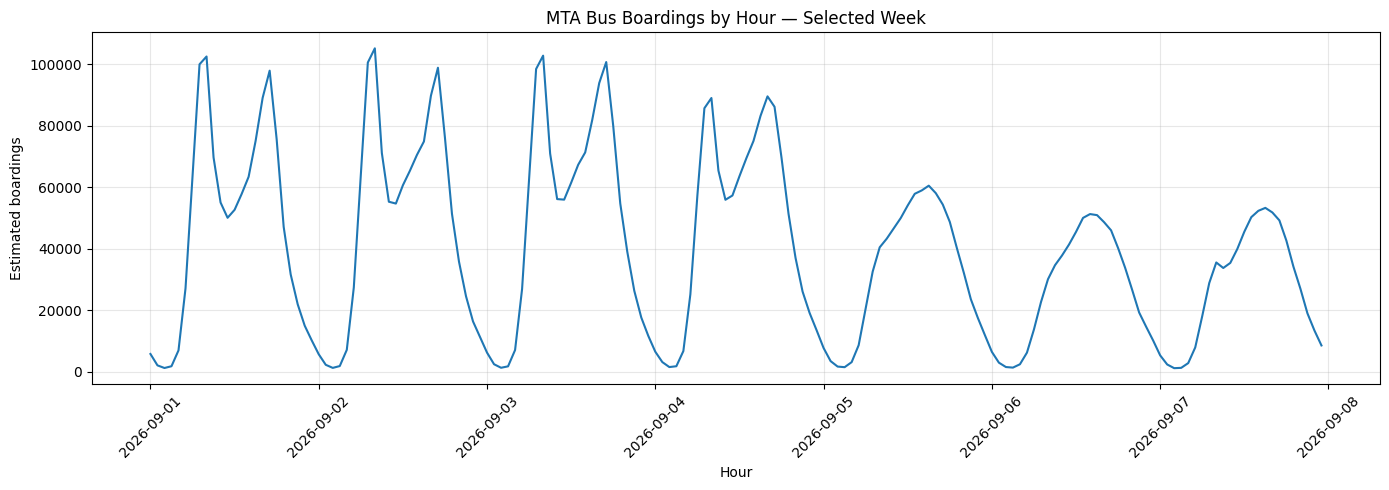

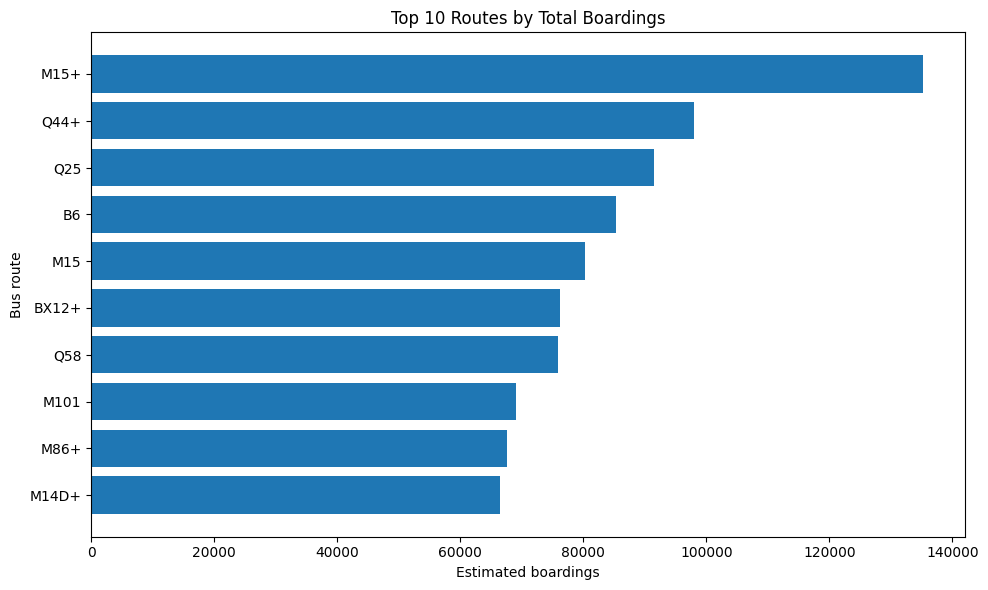

In [ ]:

import matplotlib.pyplot as plt

# Network-wide demand by hour
plt.figure(figsize=(14, 5))
plt.plot(
    hourly_summary["transit_timestamp"],
    hourly_summary["ridership"]
)
plt.title("MTA Bus Boardings by Hour — Selected Week")
plt.xlabel("Hour")
plt.ylabel("Estimated boardings")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Top 10 routes
top_routes = route_summary.head(10).sort_values("total_boardings")

plt.figure(figsize=(10, 6))
plt.barh(
    top_routes.index.astype(str),
    top_routes["total_boardings"]
)
plt.title("Top 10 Routes by Total Boardings")
plt.xlabel("Estimated boardings")
plt.ylabel("Bus route")
plt.tight_layout()
plt.show()


In [ ]:

OUTPUT_FILE = "mta_bus_ridership_validated_week.csv"

df.to_csv(OUTPUT_FILE, index=False)

print(f"Saved {len(df):,} validated records to {OUTPUT_FILE}")

# Download the CSV from Colab to your computer.
from google.colab import files
files.download(OUTPUT_FILE)


Saved 75,600 validated records to mta_bus_ridership_validated_week.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

print("=" * 55)
print("1. DATASET SHAPE AND COLUMNS")
print("=" * 55)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes.to_string())

print("\n" + "=" * 55)
print("2. TIMESTAMP AND ROUTE COVERAGE")
print("=" * 55)
print("Start:", df["transit_timestamp"].min())
print("End:", df["transit_timestamp"].max())
print("Unique timestamps:", df["transit_timestamp"].nunique())
print("Unique routes:", df["bus_route"].nunique())
print("Rows per route:")
print(df.groupby("bus_route").size().describe().to_string())

print("\n" + "=" * 55)
print("3. RIDERSHIP STATISTICS")
print("=" * 55)
print(df["ridership"].describe().to_string())
print("Zero-ridership rows:", int((df["ridership"] == 0).sum()))
print("Negative-ridership rows:", int((df["ridership"] < 0).sum()))
print("Duplicate route-hour rows:",
      int(df.duplicated(
          ["transit_timestamp", "bus_route"]
      ).sum()))

print("\n" + "=" * 55)
print("4. HOURLY NETWORK TOTALS")
print("=" * 55)
print(hourly_summary["ridership"].describe().to_string())
print("\nFirst 5 rows:")
print(hourly_summary.head().to_string(index=False))
print("\nLast 5 rows:")
print(hourly_summary.tail().to_string(index=False))

print("\n" + "=" * 55)
print("5. TOP 10 ROUTES")
print("=" * 55)
print(route_summary.head(10).to_string())


1. DATASET SHAPE AND COLUMNS
Shape: (75600, 3)
Columns: ['transit_timestamp', 'bus_route', 'ridership']

Data types:
transit_timestamp    datetime64[ns]
bus_route            string[python]
ridership                     int64

2. TIMESTAMP AND ROUTE COVERAGE
Start: 2026-09-01 00:00:00
End: 2026-09-07 23:00:00
Unique timestamps: 168
Unique routes: 450
Rows per route:
count    450.0
mean     168.0
std        0.0
min      168.0
25%      168.0
50%      168.0
75%      168.0
max      168.0

3. RIDERSHIP STATISTICS
count    75600.000000
mean        88.747302
std        157.863925
min          0.000000
25%          0.000000
50%         16.000000
75%        112.000000
max       2993.000000
Zero-ridership rows: 31262
Negative-ridership rows: 0
Duplicate route-hour rows: 0

4. HOURLY NETWORK TOTALS
count       168.000000
mean      39936.285714
std       29575.540328
min        1127.000000
25%       11541.500000
50%       39490.500000
75%       59375.250000
max      105240.000000

First 5 rows:
  t

In [ ]:

import requests
import pandas as pd
import time

API_URL = "https://data.ny.gov/resource/gxb3-akrn.json"

# Eight weeks ending at the end of the week already validated.
START = pd.Timestamp("2026-07-14")
END = pd.Timestamp("2026-09-08")  # Exclusive

PAGE_SIZE = 50000
weekly_frames = []

def fetch_week(start, end):
    rows = []
    offset = 0

    while True:
        params = {
            "$select": (
                "transit_timestamp, bus_route, "
                "sum(ridership) as ridership"
            ),
            "$where": (
                f"transit_timestamp >= '{start:%Y-%m-%dT%H:%M:%S}' "
                f"AND transit_timestamp < '{end:%Y-%m-%dT%H:%M:%S}'"
            ),
            "$group": "transit_timestamp, bus_route",
            "$order": "transit_timestamp, bus_route",
            "$limit": PAGE_SIZE,
            "$offset": offset
        }

        response = requests.get(
            API_URL,
            params=params,
            timeout=180
        )
        response.raise_for_status()
        batch = response.json()

        if not batch:
            break

        rows.extend(batch)
        offset += len(batch)

        print(f"  Retrieved {len(rows):,} rows for this week")

        if len(batch) < PAGE_SIZE:
            break

        time.sleep(0.3)

    return pd.DataFrame(rows)

week_start = START

while week_start < END:
    week_end = min(
        week_start + pd.Timedelta(days=7),
        END
    )

    print(f"\nFetching {week_start.date()} to {week_end.date()}")

    part = fetch_week(week_start, week_end)

    if not part.empty:
        weekly_frames.append(part)

    week_start = week_end

    # Small pause between weekly requests.
    time.sleep(0.5)

if not weekly_frames:
    raise RuntimeError("No historical records were retrieved.")

df8 = pd.concat(weekly_frames, ignore_index=True)

df8["transit_timestamp"] = pd.to_datetime(
    df8["transit_timestamp"], errors="coerce"
)
df8["bus_route"] = df8["bus_route"].astype("string")
df8["ridership"] = pd.to_numeric(
    df8["ridership"], errors="coerce"
)

print("\nExpanded dataset shape:", df8.shape)
print("Date range:",
      df8["transit_timestamp"].min(),
      "to",
      df8["transit_timestamp"].max())
print("Unique routes:", df8["bus_route"].nunique())



Fetching 2026-07-14 to 2026-07-21
  Retrieved 50,000 rows for this week
  Retrieved 75,600 rows for this week

Fetching 2026-07-21 to 2026-07-28
  Retrieved 50,000 rows for this week
  Retrieved 75,600 rows for this week

Fetching 2026-07-28 to 2026-08-04
  Retrieved 50,000 rows for this week
  Retrieved 75,600 rows for this week

Fetching 2026-08-04 to 2026-08-11
  Retrieved 50,000 rows for this week
  Retrieved 75,600 rows for this week

Fetching 2026-08-11 to 2026-08-18
  Retrieved 50,000 rows for this week
  Retrieved 75,600 rows for this week

Fetching 2026-08-18 to 2026-08-25
  Retrieved 50,000 rows for this week
  Retrieved 75,600 rows for this week

Fetching 2026-08-25 to 2026-09-01
  Retrieved 50,000 rows for this week
  Retrieved 75,600 rows for this week

Fetching 2026-09-01 to 2026-09-08
  Retrieved 50,000 rows for this week
  Retrieved 75,600 rows for this week

Expanded dataset shape: (604800, 3)
Date range: 2026-07-14 00:00:00 to 2026-09-07 23:00:00
Unique routes: 450


In [ ]:

assert df8[[
    "transit_timestamp", "bus_route", "ridership"
]].notna().all().all(), "Missing values detected"

assert (df8["ridership"] >= 0).all(), (
    "Negative ridership detected"
)

assert not df8.duplicated(
    ["transit_timestamp", "bus_route"]
).any(), "Duplicate route-hour records detected"

# Inspect coverage by route and week.
df8["week_start"] = (
    df8["transit_timestamp"]
       .dt.normalize()
       - pd.to_timedelta(
           df8["transit_timestamp"].dt.dayofweek,
           unit="D"
       )
)

weekly_route_counts = df8.groupby(
    ["week_start", "bus_route"]
).size()

print("Number of weeks:", df8["week_start"].nunique())
print("Rows:", f"{len(df8):,}")
print("Unique routes:", df8["bus_route"].nunique())
print("Route-week observation summary:")
print(weekly_route_counts.describe())

print("\nMissing route-hour combinations must be assessed")
print("against the expected service schedule, not assumed")
print("to be zero-demand observations.")

df8 = df8.sort_values(
    ["bus_route", "transit_timestamp"]
).reset_index(drop=True)

df8.to_csv("mta_ridership_8_weeks.csv", index=False)
print("\nSaved mta_ridership_8_weeks.csv")


Number of weeks: 9
Rows: 604,800
Unique routes: 450
Route-week observation summary:
count    4050.000000
mean      149.333333
std        44.945015
min        24.000000
25%       168.000000
50%       168.000000
75%       168.000000
max       168.000000
dtype: float64

Missing route-hour combinations must be assessed
against the expected service schedule, not assumed
to be zero-demand observations.

Saved mta_ridership_8_weeks.csv


In [ ]:

import pandas as pd

coverage = df8.copy()

coverage["calendar_week"] = (
    coverage["transit_timestamp"].dt.to_period("W-SUN")
)

weekly_report = (
    coverage.groupby("calendar_week")
    .agg(
        first_timestamp=("transit_timestamp", "min"),
        last_timestamp=("transit_timestamp", "max"),
        unique_hours=("transit_timestamp", "nunique"),
        records=("ridership", "size"),
        routes=("bus_route", "nunique"),
        expected_route_hours=(
            "bus_route",
            lambda s: s.nunique() * 168
        )
    )
    .reset_index()
)

weekly_report["full_week"] = (
    (weekly_report["unique_hours"] == 168)
    & (weekly_report["records"] == 450 * 168)
)

display(weekly_report.to_string(index=False))

print("\nOverall date range:")
print(df8["transit_timestamp"].min(), "to",
      df8["transit_timestamp"].max())

print("\nRows per route:")
route_counts = df8.groupby("bus_route").size()
print(route_counts.describe())

print("\nHourly timestamp gaps in the complete dataset:")
all_hours = pd.date_range(
    df8["transit_timestamp"].min(),
    df8["transit_timestamp"].max(),
    freq="h"
)
observed_hours = pd.DatetimeIndex(
    df8["transit_timestamp"].unique()
).sort_values()

print("Expected timestamps:", len(all_hours))
print("Observed timestamps:", len(observed_hours))
print("Missing network-level timestamps:",
      len(all_hours.difference(observed_hours)))


'        calendar_week first_timestamp      last_timestamp  unique_hours  records  routes  expected_route_hours  full_week\n2026-07-13/2026-07-19      2026-07-14 2026-07-19 23:00:00           144    64800     450                 75600      False\n2026-07-20/2026-07-26      2026-07-20 2026-07-26 23:00:00           168    75600     450                 75600       True\n2026-07-27/2026-08-02      2026-07-27 2026-08-02 23:00:00           168    75600     450                 75600       True\n2026-08-03/2026-08-09      2026-08-03 2026-08-09 23:00:00           168    75600     450                 75600       True\n2026-08-10/2026-08-16      2026-08-10 2026-08-16 23:00:00           168    75600     450                 75600       True\n2026-08-17/2026-08-23      2026-08-17 2026-08-23 23:00:00           168    75600     450                 75600       True\n2026-08-24/2026-08-30      2026-08-24 2026-08-30 23:00:00           168    75600     450                 75600       True\n2026-08-31/2026


Overall date range:
2026-07-14 00:00:00 to 2026-09-07 23:00:00

Rows per route:
count     450.0
mean     1344.0
std         0.0
min      1344.0
25%      1344.0
50%      1344.0
75%      1344.0
max      1344.0
dtype: float64

Hourly timestamp gaps in the complete dataset:
Expected timestamps: 1344
Observed timestamps: 1344
Missing network-level timestamps: 0


# Phase 2

In [ ]:

import numpy as np
import pandas as pd

# Keep only the columns needed for forecasting.
data = df8[
    ["transit_timestamp", "bus_route", "ridership"]
].copy()

data["transit_timestamp"] = pd.to_datetime(
    data["transit_timestamp"]
)

data = data.sort_values(
    ["transit_timestamp", "bus_route"]
).reset_index(drop=True)

# Calendar and time-of-day features.
data["hour"] = data["transit_timestamp"].dt.hour
data["day_of_week"] = data["transit_timestamp"].dt.dayofweek
data["is_weekend"] = (
    data["day_of_week"] >= 5
).astype(int)

data["day_of_month"] = (
    data["transit_timestamp"].dt.day
)

# Route identifier: use one-hot encoding in the model pipeline.
data["bus_route"] = data["bus_route"].astype(str)

print("Prepared shape:", data.shape)
print("\nColumns:")
print(data.columns.tolist())
print("\nSample rows:")
display(data.head())


Prepared shape: (604800, 7)

Columns:
['transit_timestamp', 'bus_route', 'ridership', 'hour', 'day_of_week', 'is_weekend', 'day_of_month']

Sample rows:


,transit_timestamp,bus_route,ridership,hour,day_of_week,is_weekend,day_of_month
0,2026-07-14,B1,31,0,1,0,14
1,2026-07-14,B100,1,0,1,0,14
2,2026-07-14,B101,0,0,1,0,14
3,2026-07-14,B102,0,0,1,0,14
4,2026-07-14,B103,32,0,1,0,14


In [ ]:

# Verify the expected route-hour grid before using row-based lags.
route_counts = data.groupby("bus_route").size()
assert route_counts.nunique() == 1, (
    "Routes have different record counts; investigate missing rows."
)

# Create lags within each route, ordered by time.
data = data.sort_values(
    ["bus_route", "transit_timestamp"]
).reset_index(drop=True)

data["lag_24h"] = (
    data.groupby("bus_route")["ridership"].shift(24)
)

data["lag_168h"] = (
    data.groupby("bus_route")["ridership"].shift(168)
)

print("Rows before lag removal:", len(data))
print("Missing lag values:")
print(data[["lag_24h", "lag_168h"]].isna().sum())

model_data = data.dropna(
    subset=["lag_24h", "lag_168h"]
).copy()

print("Rows available after lag removal:", len(model_data))
display(model_data.head())


Rows before lag removal: 604800
Missing lag values:
lag_24h     10800
lag_168h    75600
dtype: int64
Rows available after lag removal: 529200


,transit_timestamp,bus_route,ridership,hour,day_of_week,is_weekend,day_of_month,lag_24h,lag_168h
168,2026-07-21 00:00:00,B1,38,0,1,0,21,20.0,31.0
169,2026-07-21 01:00:00,B1,17,1,1,0,21,11.0,5.0
170,2026-07-21 02:00:00,B1,4,2,1,0,21,7.0,10.0
171,2026-07-21 03:00:00,B1,10,3,1,0,21,15.0,14.0
172,2026-07-21 04:00:00,B1,33,4,1,0,21,33.0,28.0


In [ ]:

# Use full calendar days for clear chronological evaluation.
timestamps = np.sort(
    model_data["transit_timestamp"].unique()
)

assert len(timestamps) == 1344 - 168, (
    f"Unexpected timestamp count after lags: {len(timestamps)}"
)

train_end = pd.Timestamp("2026-08-25 00:00:00")
validation_end = pd.Timestamp("2026-09-01 00:00:00")

train = model_data[
    model_data["transit_timestamp"] < train_end
].copy()

validation = model_data[
    (model_data["transit_timestamp"] >= train_end)
    & (model_data["transit_timestamp"] < validation_end)
].copy()

test = model_data[
    model_data["transit_timestamp"] >= validation_end
].copy()

print("Train:", train.shape,
      train["transit_timestamp"].min(),
      "to", train["transit_timestamp"].max())

print("Validation:", validation.shape,
      validation["transit_timestamp"].min(),
      "to", validation["transit_timestamp"].max())

print("Test:", test.shape,
      test["transit_timestamp"].min(),
      "to", test["transit_timestamp"].max())

assert train["transit_timestamp"].max() < validation["transit_timestamp"].min()
assert validation["transit_timestamp"].max() < test["transit_timestamp"].min()


Train: (378000, 9) 2026-07-21 00:00:00 to 2026-08-24 23:00:00
Validation: (75600, 9) 2026-08-25 00:00:00 to 2026-08-31 23:00:00
Test: (75600, 9) 2026-09-01 00:00:00 to 2026-09-07 23:00:00


In [ ]:

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Route IDs: convert categories to numeric codes.
# These codes are identifiers, not ordinal demand values.
for frame in (train, validation, test):
    frame["route_code"] = frame["bus_route"].astype("category").cat.codes

features_fast = [
    "route_code",
    "hour",
    "day_of_week",
    "is_weekend",
    "day_of_month",
    "lag_24h",
    "lag_168h",
]

target = "ridership"

X_train = train[features_fast]
y_train = train[target]
X_val = validation[features_fast]
y_val = validation[target]

def evaluate(name, actual, predicted):
    predicted = np.maximum(0, predicted)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = (
        np.abs(np.asarray(actual) - predicted).sum()
        / max(np.asarray(actual).sum(), 1)
    ) * 100

    return {
        "model": name,
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "WAPE_percent": round(wape, 3),
    }

results = []

# Baseline: same route, same hour, one week earlier.
results.append(
    evaluate("Weekly seasonal baseline", y_val, validation["lag_168h"])
)

# Smaller Random Forest on a sample to keep runtime manageable.
sample_train = train.sample(
    n=min(100_000, len(train)),
    random_state=42
)

rf = RandomForestRegressor(
    n_estimators=40,
    max_depth=18,
    min_samples_leaf=5,
    max_features=0.8,
    n_jobs=-1,
    random_state=42
)

start = time.time()
rf.fit(sample_train[features_fast], sample_train[target])
rf_pred = rf.predict(X_val)

results.append(evaluate("Random Forest (sampled)", y_val, rf_pred))
print(f"Random Forest finished in {(time.time()-start)/60:.1f} minutes")

# Gradient boosting, with a limited number of iterations.
hgb = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.08,
    max_leaf_nodes=20,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

start = time.time()
hgb.fit(X_train, y_train)
hgb_pred = hgb.predict(X_val)

results.append(evaluate("HistGradientBoosting", y_val, hgb_pred))
print(f"HistGradientBoosting finished in {(time.time()-start)/60:.1f} minutes")

results_df = pd.DataFrame(results).sort_values("WAPE_percent")
display(results_df)


Random Forest finished in 0.2 minutes
HistGradientBoosting finished in 0.1 minutes


,model,MAE,RMSE,WAPE_percent
1,Random Forest (sampled),12.252,25.961,12.987
2,HistGradientBoosting,12.449,26.506,13.195
0,Weekly seasonal baseline,12.788,26.975,13.554


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

X_test = test[features_fast]
y_test = test["ridership"]

def test_metrics(name, actual, predicted):
    actual = np.asarray(actual)
    predicted = np.maximum(0, np.asarray(predicted))

    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE (%)": (
            np.abs(actual - predicted).sum()
            / max(actual.sum(), 1)
        ) * 100
    }

test_results = pd.DataFrame([
    test_metrics(
        "Random Forest (sampled)",
        y_test,
        rf.predict(X_test)
    ),
    test_metrics(
        "HistGradientBoosting",
        y_test,
        hgb.predict(X_test)
    ),
    test_metrics(
        "Weekly seasonal baseline",
        y_test,
        test["lag_168h"]
    )
])

display(test_results.round(3))

,Model,MAE,RMSE,WAPE (%)
0,Random Forest (sampled),18.002,47.020,20.284
1,HistGradientBoosting,18.594,49.300,20.951
2,Weekly seasonal baseline,19.043,49.312,21.457


In [ ]:
import numpy as np
import pandas as pd

# Test-set predictions from the trained Random Forest
diagnostics = test[
    ["transit_timestamp", "bus_route", "ridership",
     "hour", "day_of_week", "is_weekend"]
].copy()

diagnostics["predicted_ridership"] = np.maximum(
    0, rf.predict(test[features_fast])
)

diagnostics["absolute_error"] = np.abs(
    diagnostics["ridership"] -
    diagnostics["predicted_ridership"]
)

diagnostics["error"] = (
    diagnostics["predicted_ridership"] -
    diagnostics["ridership"]
)

diagnostics["demand_period"] = np.select(
    [
        diagnostics["hour"].between(7, 9),
        diagnostics["hour"].between(16, 19)
    ],
    ["Morning peak", "Evening peak"],
    default="Off-peak"
)

# Performance by demand period
period_results = diagnostics.groupby(
    "demand_period"
).apply(
    lambda g: pd.Series({
        "records": len(g),
        "MAE": g["absolute_error"].mean(),
        "WAPE (%)": (
            g["absolute_error"].sum()
            / max(g["ridership"].sum(), 1)
        ) * 100,
        "actual_total": g["ridership"].sum(),
        "predicted_total": g["predicted_ridership"].sum()
    }),
    include_groups=False
).round(3)

display(period_results)

# Routes with the highest absolute prediction error
route_results = diagnostics.groupby("bus_route").apply(
    lambda g: pd.Series({
        "actual_total": g["ridership"].sum(),
        "MAE": g["absolute_error"].mean(),
        "WAPE (%)": (
            g["absolute_error"].sum()
            / max(g["ridership"].sum(), 1)
        ) * 100
    }),
    include_groups=False
).round(3)

display(
    route_results.sort_values("MAE", ascending=False).head(15)
)

,records,MAE,WAPE (%),actual_total,predicted_total
demand_period,,,,,
Evening peak,12600.0,29.210,20.444,1800275.0,1959294.875
Morning peak,9450.0,31.856,22.075,1363709.0,1517337.527
Off-peak,53550.0,12.920,19.515,3545312.0,3767184.224


,actual_total,MAE,WAPE (%)
bus_route,,,
M15+,135257.0,102.889,12.780
Q25,91560.0,94.980,17.427
B46+,48498.0,85.664,29.674
BX12+,76242.0,83.697,18.443
B41,57696.0,78.372,22.820
B6,85269.0,76.409,15.054
B82+,31693.0,72.426,38.392
Q27,65412.0,69.994,17.977
M15,80329.0,69.471,14.529


In [ ]:
import numpy as np
import pandas as pd

diagnostics = test[
    ["transit_timestamp", "bus_route", "ridership", "hour"]
].copy()

diagnostics["predicted_ridership"] = np.maximum(
    0, rf.predict(test[features_fast])
)

diagnostics["absolute_error"] = np.abs(
    diagnostics["ridership"] -
    diagnostics["predicted_ridership"]
)

diagnostics["demand_period"] = np.select(
    [
        diagnostics["hour"].between(7, 9),
        diagnostics["hour"].between(16, 19)
    ],
    ["Morning peak", "Evening peak"],
    default="Off-peak"
)

def summarise(group):
    actual = group["ridership"].sum()
    abs_error = group["absolute_error"].sum()

    return pd.Series({
        "records": len(group),
        "MAE": group["absolute_error"].mean(),
        "WAPE (%)": 100 * abs_error / max(actual, 1),
        "actual_total": actual,
        "predicted_total": group["predicted_ridership"].sum()
    })

period_results = (
    diagnostics.groupby("demand_period")
    .apply(summarise)
    .round(3)
)

print("PERFORMANCE BY DEMAND PERIOD")
display(period_results)

route_results = (
    diagnostics.groupby("bus_route")
    .apply(summarise)
    .round(3)
)

print("15 ROUTES WITH HIGHEST WAPE")
display(
    route_results.sort_values("WAPE (%)", ascending=False).head(15)
)

PERFORMANCE BY DEMAND PERIOD


/tmp/ipykernel_960/4254186180.py:40: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(summarise)


,records,MAE,WAPE (%),actual_total,predicted_total
demand_period,,,,,
Evening peak,12600.0,29.210,20.444,1800275.0,1959294.875
Morning peak,9450.0,31.856,22.075,1363709.0,1517337.527
Off-peak,53550.0,12.920,19.515,3545312.0,3767184.224


/tmp/ipykernel_960/4254186180.py:49: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(summarise)


15 ROUTES WITH HIGHEST WAPE


,records,MAE,WAPE (%),actual_total,predicted_total
bus_route,,,,,
T426,168.0,0.308,5172.105,0.0,51.721
BX95,168.0,0.171,2866.058,0.0,28.661
T430,168.0,0.141,2360.951,0.0,23.610
BX18,168.0,0.056,934.382,0.0,9.344
B111,168.0,0.055,931.934,0.0,9.319
QM3,168.0,0.042,706.627,0.0,7.066
B116,168.0,0.039,658.004,0.0,6.580
B101,168.0,0.036,610.543,0.0,6.105
M14D,168.0,0.035,592.553,0.0,5.926


In [ ]:
# Route-level evaluation with zero-ridership routes handled separately

route_results = (
    diagnostics.groupby("bus_route")
    .agg(
        records=("ridership", "size"),
        actual_total=("ridership", "sum"),
        predicted_total=("predicted_ridership", "sum"),
        MAE=("absolute_error", "mean"),
        absolute_error_total=("absolute_error", "sum")
    )
)

route_results["WAPE (%)"] = np.where(
    route_results["actual_total"] > 0,
    100 * route_results["absolute_error_total"]
    / route_results["actual_total"],
    np.nan
)

route_results["evaluation_status"] = np.where(
    route_results["actual_total"] > 0,
    "Positive actual ridership",
    "Zero actual ridership"
)

print("Routes with positive actual ridership — highest WAPE:")
display(
    route_results[
        route_results["actual_total"] > 0
    ]
    .sort_values("WAPE (%)", ascending=False)
    .head(15)
    .round(3)
)

print("Routes with zero actual ridership:")
display(
    route_results[
        route_results["actual_total"] == 0
    ][
        ["records", "actual_total", "predicted_total",
         "MAE", "evaluation_status"]
    ]
    .sort_values("predicted_total", ascending=False)
    .head(15)
    .round(3)
)

Routes with positive actual ridership — highest WAPE:


,records,actual_total,predicted_total,MAE,absolute_error_total,WAPE (%),evaluation_status
bus_route,,,,,,,
Q70+,168,69,157.453,1.025,172.128,249.461,Positive actual ridership
S86,168,228,336.990,1.317,221.315,97.068,Positive actual ridership
S81,168,385,588.379,1.792,301.133,78.216,Positive actual ridership
S84,168,314,484.000,1.425,239.437,76.254,Positive actual ridership
S94,168,1219,1768.785,5.499,923.878,75.790,Positive actual ridership
QM21,168,383,607.488,1.607,269.925,70.476,Positive actual ridership
BX46,168,1423,1746.644,5.911,993.057,69.786,Positive actual ridership
S96,168,1463,2036.337,5.873,986.718,67.445,Positive actual ridership
BX20,168,975,1123.012,3.837,644.658,66.119,Positive actual ridership


Routes with zero actual ridership:


,records,actual_total,predicted_total,MAE,evaluation_status
bus_route,,,,,
T426,168,0,51.721,0.308,Zero actual ridership
BX95,168,0,28.661,0.171,Zero actual ridership
T430,168,0,23.610,0.141,Zero actual ridership
BX18,168,0,9.344,0.056,Zero actual ridership
B111,168,0,9.319,0.055,Zero actual ridership
QM3,168,0,7.066,0.042,Zero actual ridership
B116,168,0,6.580,0.039,Zero actual ridership
B101,168,0,6.105,0.036,Zero actual ridership
M14D,168,0,5.926,0.035,Zero actual ridership


In [ ]:
import pandas as pd

zero_routes = (
    route_results.loc[
        route_results["actual_total"] == 0
    ].index.tolist()
)

# Compare the test week with the preceding week
df_check = df8.copy()
df_check["transit_timestamp"] = pd.to_datetime(
    df_check["transit_timestamp"]
)

test_start = pd.Timestamp("2026-09-01")
test_end = pd.Timestamp("2026-09-08")
previous_start = pd.Timestamp("2026-08-25")

zero_route_history = df_check[
    df_check["bus_route"].isin(zero_routes)
    & (df_check["transit_timestamp"] >= previous_start)
    & (df_check["transit_timestamp"] < test_end)
].copy()

zero_route_history["period"] = (
    zero_route_history["transit_timestamp"]
    .ge(test_start)
    .map({True: "Test week", False: "Previous week"})
)

history_summary = (
    zero_route_history.groupby(["bus_route", "period"])
    .agg(
        records=("ridership", "size"),
        actual_total=("ridership", "sum"),
        nonzero_hours=("ridership", lambda s: (s > 0).sum())
    )
    .reset_index()
)

display(
    history_summary.sort_values(["bus_route", "period"])
)

,bus_route,period,records,actual_total,nonzero_hours
0,B101,Previous week,168,0,0
1,B101,Test week,168,0,0
2,B102,Previous week,168,0,0
3,B102,Test week,168,0,0
4,B106,Previous week,168,0,0
...,...,...,...,...,...
205,X7,Test week,168,0,0
206,X8,Previous week,168,0,0
207,X8,Test week,168,0,0
208,X9,Previous week,168,0,0


In [ ]:
# Check ridership distribution in the original 8-week dataset

print("Total records:", len(df8))
print("Unique routes:", df8["bus_route"].nunique())

print("\nRidership distribution:")
display(df8["ridership"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame())

print("\nZero vs positive ridership:")
display(
    df8.assign(
        ridership_status=np.where(
            df8["ridership"] == 0,
            "Zero",
            "Positive"
        )
    )["ridership_status"]
    .value_counts()
    .to_frame("records")
    .assign(
        percentage=lambda x:
        (x["records"] / len(df8) * 100).round(2)
    )
)

Total records: 604800
Unique routes: 450

Ridership distribution:


,ridership
count,604800.000000
mean,95.242221
std,165.955956
min,0.000000
25%,0.000000
50%,18.000000
75%,123.000000
90%,298.000000
95%,437.000000
99%,744.000000



Zero vs positive ridership:


,records,percentage
ridership_status,,
Positive,361309,59.74
Zero,243491,40.26


In [ ]:
route_activity = (
    df8.groupby("bus_route")
    .agg(
        total_ridership=("ridership", "sum"),
        positive_hours=("ridership", lambda s: (s > 0).sum()),
        observed_hours=("ridership", "size"),
        average_ridership=("ridership", "mean"),
        maximum_hourly_ridership=("ridership", "max")
    )
)

route_activity["positive_hour_percentage"] = (
    route_activity["positive_hours"]
    / route_activity["observed_hours"] * 100
).round(2)

print("Routes with zero ridership across the full dataset:")
display(
    route_activity[
        route_activity["total_ridership"] == 0
    ].sort_values("bus_route")
)

print("Routes with positive ridership across the full dataset:")
display(
    route_activity[
        route_activity["total_ridership"] > 0
    ].sort_values("total_ridership", ascending=False).head(15)
)

Routes with zero ridership across the full dataset:


,total_ridership,positive_hours,observed_hours,average_ridership,maximum_hourly_ridership,positive_hour_percentage
bus_route,,,,,,
B101,0,0,1344,0.0,0,0.0
B102,0,0,1344,0.0,0,0.0
B106,0,0,1344,0.0,0,0.0
B116,0,0,1344,0.0,0,0.0
B90,0,0,1344,0.0,0,0.0
...,...,...,...,...,...,...
X64,0,0,1344,0.0,0,0.0
X68,0,0,1344,0.0,0,0.0
X7,0,0,1344,0.0,0,0.0


Routes with positive ridership across the full dataset:


,total_ridership,positive_hours,observed_hours,average_ridership,maximum_hourly_ridership,positive_hour_percentage
bus_route,,,,,,
M15+,1129634,1193,1344,840.501488,3189,88.76
Q44+,809898,1343,1344,602.602679,1533,99.93
Q25,783855,1343,1344,583.225446,1725,99.93
B6,728195,1344,1344,541.811756,1455,100.00
M15,671921,1344,1344,499.941220,1131,100.00
Q58,650305,1344,1344,483.857887,1169,100.00
BX12+,642439,1160,1344,478.005208,1534,86.31
M86+,585656,1340,1344,435.755952,1413,99.70
M101,571978,1344,1344,425.578869,1229,100.00


In [ ]:
import pandas as pd
import numpy as np

# Identify routes with at least one positive ridership observation
route_totals = df8.groupby("bus_route")["ridership"].sum()

active_routes = route_totals[route_totals > 0].index

df_active = (
    df8[df8["bus_route"].isin(active_routes)]
    .copy()
    .sort_values(["bus_route", "transit_timestamp"])
    .reset_index(drop=True)
)

print("Original routes:", df8["bus_route"].nunique())
print("Routes in experimental subset:", df_active["bus_route"].nunique())
print("Original records:", len(df8))
print("Subset records:", len(df_active))
print(
    "Remaining zero-ridership records:",
    (df_active["ridership"] == 0).sum()
)
print(
    "Remaining zero-ridership percentage:",
    round((df_active["ridership"] == 0).mean() * 100, 2),
    "%"
)

Original routes: 450
Routes in experimental subset: 354
Original records: 604800
Subset records: 475776
Remaining zero-ridership records: 114467
Remaining zero-ridership percentage: 24.06 %


In [ ]:
import pandas as pd
import numpy as np

df_model = df_active.copy()

df_model["transit_timestamp"] = pd.to_datetime(
    df_model["transit_timestamp"]
)

df_model = df_model.sort_values(
    ["bus_route", "transit_timestamp"]
).reset_index(drop=True)

# Time-based features
df_model["hour"] = df_model["transit_timestamp"].dt.hour
df_model["day_of_week"] = df_model["transit_timestamp"].dt.dayofweek
df_model["is_weekend"] = (
    df_model["day_of_week"] >= 5
).astype(int)
df_model["day_of_month"] = df_model["transit_timestamp"].dt.day

# Route-specific lag features
grouped = df_model.groupby("bus_route")["ridership"]

df_model["lag_24h"] = grouped.shift(24)
df_model["lag_168h"] = grouped.shift(168)

# Remove rows without sufficient history
df_model = df_model.dropna(
    subset=["lag_24h", "lag_168h"]
).copy()

# Chronological splits
train = df_model[
    df_model["transit_timestamp"] < "2026-08-25"
].copy()

validation = df_model[
    (df_model["transit_timestamp"] >= "2026-08-25")
    & (df_model["transit_timestamp"] < "2026-09-01")
].copy()

test = df_model[
    (df_model["transit_timestamp"] >= "2026-09-01")
    & (df_model["transit_timestamp"] < "2026-09-08")
].copy()

print("Model rows:", len(df_model))
print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

for name, frame in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(
        name,
        "| Routes:", frame["bus_route"].nunique(),
        "| Start:", frame["transit_timestamp"].min(),
        "| End:", frame["transit_timestamp"].max()
    )

Model rows: 416304
Train: (297360, 10)
Validation: (59472, 10)
Test: (59472, 10)
Train | Routes: 354 | Start: 2026-07-21 00:00:00 | End: 2026-08-24 23:00:00
Validation | Routes: 354 | Start: 2026-08-25 00:00:00 | End: 2026-08-31 23:00:00
Test | Routes: 354 | Start: 2026-09-01 00:00:00 | End: 2026-09-07 23:00:00


In [ ]:
print("Active dataset rows:", len(df_active))
print("Feature dataset rows:", len(df_model))
print("Rows removed by lagging:", len(df_active) - len(df_model))

# Check records per route after feature engineering
route_row_counts = df_model.groupby("bus_route").size()

print("\nRows per route after lagging:")
print(route_row_counts.describe())

print("\nRoutes with unexpected row counts:")
print(route_row_counts[route_row_counts != 1176].head(20))

# Verify split totals and date ranges
print("\nSplit total:", len(train) + len(validation) + len(test))
print("Feature rows:", len(df_model))
print("Split rows match:", len(train) + len(validation) + len(test) == len(df_model))

Active dataset rows: 475776
Feature dataset rows: 416304
Rows removed by lagging: 59472

Rows per route after lagging:
count     354.0
mean     1176.0
std         0.0
min      1176.0
25%      1176.0
50%      1176.0
75%      1176.0
max      1176.0
dtype: float64

Routes with unexpected row counts:
Series([], dtype: int64)

Split total: 416304
Feature rows: 416304
Split rows match: True


In [ ]:
import time
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

target = "ridership"

numeric_features = [
    "hour",
    "day_of_week",
    "is_weekend",
    "day_of_month",
    "lag_24h",
    "lag_168h"
]

categorical_features = ["bus_route"]

# Use a representative sample for a quick experiment
train_sample = train.sample(
    n=min(100_000, len(train)),
    random_state=42
)

X_train = train_sample[numeric_features + categorical_features]
y_train = train_sample[target]

X_val = validation[numeric_features + categorical_features]
y_val = validation[target]

preprocessor = ColumnTransformer(
    transformers=[
        ("route", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numeric", "passthrough", numeric_features)
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=40,
        max_depth=18,
        min_samples_leaf=5,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ))
])

start = time.time()
model.fit(X_train, y_train)
print(f"Training time: {(time.time() - start) / 60:.2f} minutes")

val_predictions = np.maximum(0, model.predict(X_val))

mae = mean_absolute_error(y_val, val_predictions)
rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
wape = (
    np.abs(y_val.to_numpy() - val_predictions).sum()
    / max(y_val.sum(), 1)
    * 100
)

print(f"Validation MAE:  {mae:.3f}")
print(f"Validation RMSE: {rmse:.3f}")
print(f"Validation WAPE: {wape:.2f}%")

Training time: 1.40 minutes
Validation MAE:  15.753
Validation RMSE: 29.495
Validation WAPE: 13.14%


In [ ]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_val = validation["ridership"].to_numpy()

# Weekly seasonal baseline
baseline_predictions = np.maximum(
    0, validation["lag_168h"].to_numpy()
)

# Random Forest predictions from your previous cell
rf_predictions = np.maximum(
    0, model.predict(
        validation[numeric_features + categorical_features]
    )
)

def evaluate_model(name, y_true, predictions):
    mae = mean_absolute_error(y_true, predictions)
    rmse = np.sqrt(mean_squared_error(y_true, predictions))
    wape = (
        np.abs(y_true - predictions).sum()
        / max(y_true.sum(), 1)
        * 100
    )
    return {
        "Model": name,
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "WAPE (%)": round(wape, 2)
    }

comparison = pd.DataFrame([
    evaluate_model("Weekly seasonal baseline", y_val, baseline_predictions),
    evaluate_model("Random Forest", y_val, rf_predictions)
])

display(comparison)


,Model,MAE,RMSE,WAPE (%)
0,Weekly seasonal baseline,16.255,30.414,13.55
1,Random Forest,15.753,29.495,13.14


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Final test evaluation
X_test = test[numeric_features + categorical_features]
y_test = test["ridership"].to_numpy()

test_predictions = np.maximum(0, model.predict(X_test))

test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_wape = (
    np.abs(y_test - test_predictions).sum()
    / max(y_test.sum(), 1)
    * 100
)

test_results = pd.DataFrame([{
    "Model": "Random Forest",
    "MAE": round(test_mae, 3),
    "RMSE": round(test_rmse, 3),
    "WAPE (%)": round(test_wape, 2)
}])

display(test_results)

print(f"Test observations: {len(y_test):,}")
print(f"Actual total ridership: {y_test.sum():,.0f}")
print(f"Predicted total ridership: {test_predictions.sum():,.0f}")


,Model,MAE,RMSE,WAPE (%)
0,Random Forest,23.17,53.321,20.54


Test observations: 59,472
Actual total ridership: 6,709,296
Predicted total ridership: 7,244,514


In [ ]:

# Build a diagnostic dataframe from the existing test predictions
diagnostics = test[
    ["bus_route", "transit_timestamp", "ridership", "hour"]
].copy()

diagnostics["actual"] = diagnostics["ridership"]
diagnostics["predicted"] = test_predictions
diagnostics["error"] = (
    diagnostics["predicted"] - diagnostics["actual"]
)
diagnostics["absolute_error"] = diagnostics["error"].abs()

print("OVERALL BIAS")
print(f"Mean signed error: {diagnostics['error'].mean():.2f}")
print(f"Total overprediction: {diagnostics['error'].sum():,.0f}")
print(
    f"Overprediction relative to actual: "
    f"{diagnostics['error'].sum() / diagnostics['actual'].sum() * 100:.2f}%"
)

# Performance by time of day
diagnostics["period"] = np.select(
    [
        diagnostics["hour"].between(7, 9),
        diagnostics["hour"].between(16, 19)
    ],
    ["Morning peak", "Evening peak"],
    default="Off-peak"
)

period_summary = diagnostics.groupby("period").apply(
    lambda g: pd.Series({
        "observations": len(g),
        "actual_total": g["actual"].sum(),
        "predicted_total": g["predicted"].sum(),
        "MAE": g["absolute_error"].mean(),
        "WAPE (%)": (
            g["absolute_error"].sum()
            / max(g["actual"].sum(), 1) * 100
        ),
        "bias (%)": (
            g["error"].sum()
            / max(g["actual"].sum(), 1) * 100
        )
    }),
    include_groups=False
).round(2)

display(period_summary)


OVERALL BIAS
Mean signed error: 9.00
Total overprediction: 535,218
Overprediction relative to actual: 7.98%


,observations,actual_total,predicted_total,MAE,WAPE (%),bias (%)
period,,,,,,
Evening peak,9912.0,1800275.0,1956853.34,37.28,20.53,8.70
Morning peak,7434.0,1363709.0,1517922.93,41.44,22.59,11.31
Off-peak,42126.0,3545312.0,3769737.41,16.63,19.76,6.33


In [ ]:

import time
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# HistGradientBoosting works efficiently with dense numeric arrays.
# Use a manageable training sample for this experiment.
experiment_sample = train.sample(
    n=min(100_000, len(train)),
    random_state=42
)

# Encode the route as a category, rather than as an ordinal number.
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_train_exp = encoder.fit_transform(
    experiment_sample[["bus_route"]]
)
X_val_exp = encoder.transform(validation[["bus_route"]])

# Append numerical features to the encoded route matrix.
X_train_num = experiment_sample[numeric_features].to_numpy(dtype=np.float32)
X_val_num = validation[numeric_features].to_numpy(dtype=np.float32)

X_train_hgb = np.column_stack([X_train_exp, X_train_num])
X_val_hgb = np.column_stack([X_val_exp, X_val_num])

y_train_exp = experiment_sample["ridership"].to_numpy()
y_val_exp = validation["ridership"].to_numpy()

hgb = HistGradientBoostingRegressor(
    max_iter=150,
    max_leaf_nodes=20,
    learning_rate=0.08,
    l2_regularization=1.0,
    early_stopping=True,
    random_state=42
)

start = time.time()
hgb.fit(X_train_hgb, y_train_exp)
print(f"Training time: {(time.time() - start) / 60:.2f} minutes")

hgb_val_predictions = np.maximum(0, hgb.predict(X_val_hgb))

def calculate_metrics(y_true, predictions):
    return {
        "MAE": round(mean_absolute_error(y_true, predictions), 3),
        "RMSE": round(
            np.sqrt(mean_squared_error(y_true, predictions)), 3
        ),
        "WAPE (%)": round(
            np.abs(y_true - predictions).sum()
            / max(y_true.sum(), 1) * 100,
            2
        ),
        "Bias (%)": round(
            (predictions.sum() - y_true.sum())
            / max(y_true.sum(), 1) * 100,
            2
        )
    }

comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        **calculate_metrics(
            y_val_exp,
            model.predict(validation[numeric_features + categorical_features])
        )
    },
    {
        "Model": "HistGradientBoosting",
        **calculate_metrics(y_val_exp, hgb_val_predictions)
    },
    {
        "Model": "Weekly seasonal baseline",
        **calculate_metrics(
            y_val_exp,
            validation["lag_168h"].to_numpy()
        )
    }
])

display(comparison)


Training time: 0.66 minutes


,Model,MAE,RMSE,WAPE (%),Bias (%)
0,Random Forest,15.753,29.495,13.14,0.10
1,HistGradientBoosting,15.801,29.962,13.18,0.45
2,Weekly seasonal baseline,16.255,30.414,13.55,-0.62


# Forecasting Agent

In [ ]:

import numpy as np
import pandas as pd

class ForecastingAgent:
    """
    Recursive hourly ridership forecasting agent.
    Uses the fitted Random Forest pipeline from the notebook.
    """

    def __init__(self, model, history):
        self.model = model
        self.history = history.copy()

        self.history["transit_timestamp"] = pd.to_datetime(
            self.history["transit_timestamp"]
        )
        self.history = self.history.sort_values(
            ["bus_route", "transit_timestamp"]
        )

        self.routes = sorted(self.history["bus_route"].unique())
        self.last_timestamp = self.history["transit_timestamp"].max()

        # Store each route's observations indexed by timestamp.
        self.route_history = {
            route: group.set_index("transit_timestamp")["ridership"].copy()
            for route, group in self.history.groupby("bus_route")
        }

    def forecast(self, horizon_hours=24):
        if horizon_hours < 1:
            raise ValueError("horizon_hours must be at least 1.")

        results = []

        for step in range(1, horizon_hours + 1):
            timestamp = (
                self.last_timestamp
                + pd.Timedelta(hours=step)
            )

            rows = []

            for route in self.routes:
                series = self.route_history[route]

                lag_24_time = timestamp - pd.Timedelta(hours=24)
                lag_168_time = timestamp - pd.Timedelta(hours=168)

                # Forecasting requires both lag observations.
                if (
                    lag_24_time not in series.index
                    or lag_168_time not in series.index
                ):
                    raise ValueError(
                        f"Missing lag history for route {route} "
                        f"at {timestamp}."
                    )

                day_of_week = timestamp.dayofweek

                rows.append({
                    "bus_route": route,
                    "hour": timestamp.hour,
                    "day_of_week": day_of_week,
                    "is_weekend": int(day_of_week >= 5),
                    "day_of_month": timestamp.day,
                    "lag_24h": float(series.loc[lag_24_time]),
                    "lag_168h": float(series.loc[lag_168_time])
                })

            features = pd.DataFrame(rows)

            predictions = np.maximum(
                0,
                self.model.predict(
                    features[numeric_features + categorical_features]
                )
            )

            step_results = pd.DataFrame({
                "transit_timestamp": timestamp,
                "bus_route": features["bus_route"],
                "predicted_ridership": predictions
            })

            results.append(step_results)

            # Store predictions so later hours can use recursive lags.
            for route, prediction in zip(
                features["bus_route"], predictions
            ):
                series = self.route_history[route]
                series.loc[timestamp] = float(prediction)

        return pd.concat(results, ignore_index=True)


# Instantiate the agent using the selected model and active-route history.
forecasting_agent = ForecastingAgent(
    model=model,
    history=df_active
)

# Generate the next 24 hours of predictions.
forecast_24h = forecasting_agent.forecast(horizon_hours=24)

print("Forecasting Agent completed.")
print("Routes:", forecast_24h["bus_route"].nunique())
print("Forecast hours:", forecast_24h["transit_timestamp"].nunique())
print("Forecast records:", f"{len(forecast_24h):,}")

display(forecast_24h.head(10))


Forecasting Agent completed.
Routes: 354
Forecast hours: 24
Forecast records: 8,496


,transit_timestamp,bus_route,predicted_ridership
0,2026-09-08,B1,24.576427
1,2026-09-08,B100,5.633194
2,2026-09-08,B103,29.685855
3,2026-09-08,B11,17.124409
4,2026-09-08,B111,0.052042
5,2026-09-08,B12,20.388314
6,2026-09-08,B13,10.211251
7,2026-09-08,B14,8.701544
8,2026-09-08,B15,46.533352
9,2026-09-08,B16,4.997061


In [ ]:

# Highest-demand routes across the forecast horizon
route_forecast_summary = (
    forecast_24h.groupby("bus_route")
    .agg(
        total_predicted=("predicted_ridership", "sum"),
        average_hourly=("predicted_ridership", "mean"),
        peak_hourly=("predicted_ridership", "max")
    )
    .sort_values("total_predicted", ascending=False)
)

print("Top 10 routes by predicted ridership:")
display(route_forecast_summary.head(10).round(2))

# Busiest predicted hours across all routes
hourly_forecast_summary = (
    forecast_24h.groupby("transit_timestamp")
    .agg(
        total_predicted_ridership=("predicted_ridership", "sum"),
        average_route_ridership=("predicted_ridership", "mean")
    )
    .sort_values("total_predicted_ridership", ascending=False)
)

print("Top 10 forecast hours:")
display(hourly_forecast_summary.head(10).round(2))


Top 10 routes by predicted ridership:


,total_predicted,average_hourly,peak_hourly
bus_route,,,
M15+,21204.95,883.54,2026.82
Q25,15970.89,665.45,1610.65
Q44+,14969.86,623.74,1312.06
B6,13780.14,574.17,1229.95
BX12+,11743.71,489.32,1228.04
Q58,11548.96,481.21,1102.57
M86+,11294.25,470.59,1220.57
M101,10582.72,440.95,1008.26
Q27,10525.11,438.55,798.64


Top 10 forecast hours:


,total_predicted_ridership,average_route_ridership
transit_timestamp,,
2026-09-08 08:00:00,93761.83,264.86
2026-09-08 07:00:00,91346.60,258.04
2026-09-08 17:00:00,89494.96,252.81
2026-09-08 16:00:00,82303.45,232.50
2026-09-08 15:00:00,70582.57,199.39
2026-09-08 18:00:00,69315.45,195.81
2026-09-08 09:00:00,63736.81,180.05
2026-09-08 14:00:00,61927.41,174.94
2026-09-08 13:00:00,57560.10,162.60


# Demand Analysis Agent

In [ ]:

import numpy as np
import pandas as pd

class DemandAnalysisAgent:
    """
    Analyses predicted hourly ridership and produces
    explainable demand-priority flags.
    """

    def __init__(self, historical_data, forecast_data):
        self.history = historical_data.copy()
        self.forecast = forecast_data.copy()

        self.history["transit_timestamp"] = pd.to_datetime(
            self.history["transit_timestamp"]
        )
        self.forecast["transit_timestamp"] = pd.to_datetime(
            self.forecast["transit_timestamp"]
        )

        self._validate_data()

    def _validate_data(self):
        required_history = {
            "bus_route", "transit_timestamp", "ridership"
        }
        required_forecast = {
            "bus_route", "transit_timestamp", "predicted_ridership"
        }

        if not required_history.issubset(self.history.columns):
            raise ValueError("Historical data is missing required columns.")

        if not required_forecast.issubset(self.forecast.columns):
            raise ValueError("Forecast data is missing required columns.")

        if self.forecast.empty:
            raise ValueError("Forecast data is empty.")

        if self.forecast["predicted_ridership"].isna().any():
            raise ValueError("Forecast contains missing predictions.")

        if (self.forecast["predicted_ridership"] < 0).any():
            raise ValueError("Forecast contains negative ridership.")

    def analyse(self):
        forecast = self.forecast.copy()
        history = self.history.copy()

        forecast["hour"] = forecast["transit_timestamp"].dt.hour
        forecast["day_of_week"] = (
            forecast["transit_timestamp"].dt.dayofweek
        )

        # 1. Summarise forecast demand by route.
        route_summary = (
            forecast.groupby("bus_route")
            .agg(
                forecast_total=("predicted_ridership", "sum"),
                forecast_average=("predicted_ridership", "mean"),
                forecast_peak=("predicted_ridership", "max")
            )
            .reset_index()
        )

        route_summary["demand_rank"] = (
            route_summary["forecast_total"]
            .rank(method="dense", ascending=False)
            .astype(int)
        )

        # 2. Aggregate forecast demand by hour.
        hourly_summary = (
            forecast.groupby("transit_timestamp")
            .agg(
                total_forecast=("predicted_ridership", "sum"),
                average_route_demand=("predicted_ridership", "mean")
            )
            .reset_index()
            .sort_values("total_forecast", ascending=False)
        )

        # 3. Classify demand periods.
        # These are time-of-day categories, not capacity assessments.
        forecast["period"] = np.select(
            [
                forecast["hour"].between(7, 9),
                forecast["hour"].between(16, 19)
            ],
            ["Morning peak", "Evening peak"],
            default="Off-peak"
        )

        period_summary = (
            forecast.groupby("period")
            .agg(
                route_hour_records=("predicted_ridership", "size"),
                predicted_total=("predicted_ridership", "sum"),
                average_route_hour=("predicted_ridership", "mean"),
                maximum_route_hour=("predicted_ridership", "max")
            )
            .reset_index()
        )

        # 4. Compare each route-hour forecast with historical
        # observations at the same hour of the week.
        history["hour"] = history["transit_timestamp"].dt.hour
        history["day_of_week"] = (
            history["transit_timestamp"].dt.dayofweek
        )

        history["hour_of_week"] = (
            history["day_of_week"] * 24 + history["hour"]
        )

        forecast["hour_of_week"] = (
            forecast["day_of_week"] * 24 + forecast["hour"]
        )

        seasonal_profile = (
            history.groupby(["bus_route", "hour_of_week"])["ridership"]
            .agg(
                historical_mean="mean",
                historical_std="std",
                historical_median="median"
            )
            .reset_index()
        )

        forecast = forecast.merge(
            seasonal_profile,
            on=["bus_route", "hour_of_week"],
            how="left"
        )

        # A historical-relative flag, not a formal anomaly diagnosis.
        # Use a floor of 1 rider to avoid division by zero.
        forecast["historical_ratio"] = (
            forecast["predicted_ridership"]
            / forecast["historical_mean"].clip(lower=1)
        )

        forecast["demand_flag"] = np.select(
            [
                forecast["historical_ratio"] >= 1.5,
                forecast["historical_ratio"] >= 1.2
            ],
            [
                "High relative to historical profile",
                "Elevated relative to historical profile"
            ],
            default="Within historical-relative range"
        )

        flagged_routes = (
            forecast[forecast["demand_flag"] !=
                     "Within historical-relative range"]
            .sort_values("historical_ratio", ascending=False)
            [[
                "transit_timestamp",
                "bus_route",
                "predicted_ridership",
                "historical_mean",
                "historical_ratio",
                "demand_flag"
            ]]
        )

        # Return transparent, inspectable outputs for the next agent.
        return {
            "route_summary": route_summary.sort_values(
                "forecast_total", ascending=False
            ),
            "hourly_summary": hourly_summary,
            "period_summary": period_summary,
            "forecast_with_flags": forecast,
            "flagged_routes": flagged_routes
        }


# Instantiate and run Agent 2
demand_agent = DemandAnalysisAgent(
    historical_data=df_active,
    forecast_data=forecast_24h
)

demand_results = demand_agent.analyse()

print("Demand Analysis Agent completed successfully.")
print("Routes analysed:", len(demand_results["route_summary"]))
print("Forecast records analysed:", len(demand_results["forecast_with_flags"]))
print("Flagged route-hour records:", len(demand_results["flagged_routes"]))


Demand Analysis Agent completed successfully.
Routes analysed: 354
Forecast records analysed: 8496
Flagged route-hour records: 489


In [ ]:

print("TOP 10 ROUTES BY PREDICTED DEMAND")
display(
    demand_results["route_summary"]
    .head(10)
    .round(2)
)

print("TOP 10 BUSIEST FORECAST HOURS")
display(
    demand_results["hourly_summary"]
    .head(10)
    .round(2)
)

print("DEMAND BY TIME-OF-DAY PERIOD")
display(
    demand_results["period_summary"]
    .round(2)
)

print("TOP 20 HISTORICAL-RELATIVE FLAGS")
display(
    demand_results["flagged_routes"]
    .head(20)
    .round(2)
)


TOP 10 ROUTES BY PREDICTED DEMAND


,bus_route,forecast_total,forecast_average,forecast_peak,demand_rank
136,M15+,21204.95,883.54,2026.82,1
195,Q25,15970.89,665.45,1610.65,2
215,Q44+,14969.86,623.74,1312.06,3
39,B6,13780.14,574.17,1229.95,4
67,BX12+,11743.71,489.32,1228.04,5
229,Q58,11548.96,481.21,1102.57,6
159,M86+,11294.25,470.59,1220.57,7
124,M101,10582.72,440.95,1008.26,8
197,Q27,10525.11,438.55,798.64,9
135,M15,10340.55,430.86,735.59,10


TOP 10 BUSIEST FORECAST HOURS


,transit_timestamp,total_forecast,average_route_demand
8,2026-09-08 08:00:00,93761.83,264.86
7,2026-09-08 07:00:00,91346.60,258.04
17,2026-09-08 17:00:00,89494.96,252.81
16,2026-09-08 16:00:00,82303.45,232.50
15,2026-09-08 15:00:00,70582.57,199.39
18,2026-09-08 18:00:00,69315.45,195.81
9,2026-09-08 09:00:00,63736.81,180.05
14,2026-09-08 14:00:00,61927.41,174.94
13,2026-09-08 13:00:00,57560.10,162.60
6,2026-09-08 06:00:00,56542.55,159.72


DEMAND BY TIME-OF-DAY PERIOD


,period,route_hour_records,predicted_total,average_route_hour,maximum_route_hour
0,Evening peak,1416,284699.67,201.06,1833.81
1,Morning peak,1062,248845.25,234.32,2026.82
2,Off-peak,6018,514507.78,85.49,1259.35


TOP 20 HISTORICAL-RELATIVE FLAGS


,transit_timestamp,bus_route,predicted_ridership,historical_mean,historical_ratio,demand_flag
775,2026-09-08 02:00:00,BX12+,14.03,0.12,14.03,High relative to historical profile
2816,2026-09-08 07:00:00,SIM4C,24.85,1.88,13.25,High relative to historical profile
1129,2026-09-08 03:00:00,BX12+,10.07,0.12,10.07,High relative to historical profile
2457,2026-09-08 06:00:00,SIM33C,9.20,0.25,9.20,High relative to historical profile
2460,2026-09-08 06:00:00,SIM3C,12.78,2.00,6.39,High relative to historical profile
337,2026-09-08 00:00:00,SIM4,7.84,1.25,6.27,High relative to historical profile
3467,2026-09-08 09:00:00,QM64,5.97,0.88,5.97,High relative to historical profile
4937,2026-09-08 13:00:00,SIM35,8.10,1.38,5.89,High relative to historical profile
4589,2026-09-08 12:00:00,SIM7,6.61,1.12,5.88,High relative to historical profile
256,2026-09-08 00:00:00,QM1,9.26,1.62,5.70,High relative to historical profile


# Operations Planning Agent

In [ ]:

# Initial simulation assumptions — not verified MTA operating data.

OPERATIONS_CONFIG = {
    "bus_capacity": 50,            # Assumed usable passenger capacity
    "planning_window_hours": 24,
    "service_hours_per_day": 18,   # Assumed daily operating span
    "target_load_factor": 0.80,    # Plan around 80% of assumed capacity
    "available_buses": 120,        # Simulated planning fleet
    "reserve_buses": 12,           # Held back as operational reserve
    "current_buses_per_route": 1,  # Simplified starting allocation
    "minimum_headway_minutes": 10,
    "maximum_headway_minutes": 60
}

print("Operations planning configuration")
for key, value in OPERATIONS_CONFIG.items():
    print(f"{key}: {value}")


Operations planning configuration
bus_capacity: 50
planning_window_hours: 24
service_hours_per_day: 18
target_load_factor: 0.8
available_buses: 120
reserve_buses: 12
current_buses_per_route: 1
minimum_headway_minutes: 10
maximum_headway_minutes: 60


In [ ]:

import numpy as np
import pandas as pd

class OperationsPlanningAgent:
    """
    Rule-based fleet and frequency planner.

    Uses forecast ridership and demand-analysis flags.
    Outputs recommendations for human review, not dispatch commands.
    """

    def __init__(self, config):
        self.config = config.copy()
        self._validate_config()

    def _validate_config(self):
        c = self.config

        if c["bus_capacity"] <= 0:
            raise ValueError("bus_capacity must be positive.")
        if not 0 < c["target_load_factor"] <= 1:
            raise ValueError("target_load_factor must be in (0, 1].")
        if c["available_buses"] < 0 or c["reserve_buses"] < 0:
            raise ValueError("Fleet counts cannot be negative.")
        if c["reserve_buses"] > c["available_buses"]:
            raise ValueError("Reserve fleet cannot exceed available fleet.")
        if c["minimum_headway_minutes"] > c["maximum_headway_minutes"]:
            raise ValueError("Minimum headway exceeds maximum headway.")

    def plan(self, forecast_data, demand_results):
        forecast = forecast_data.copy()
        route_summary = demand_results["route_summary"].copy()

        # Peak forecast for each route over the planning horizon.
        peak = (
            forecast.groupby("bus_route")["predicted_ridership"]
            .max()
            .rename("peak_hourly_forecast")
            .reset_index()
        )

        # Use the maximum hourly forecast as a conservative proxy.
        # This is NOT a passenger-load or occupancy estimate.
        planning_capacity = (
            self.config["bus_capacity"]
            * self.config["target_load_factor"]
        )

        peak["estimated_buses_required"] = np.ceil(
            peak["peak_hourly_forecast"] / planning_capacity
        ).astype(int).clip(lower=1)

        peak["current_buses_assumed"] = (
            self.config["current_buses_per_route"]
        )

        peak["additional_buses_requested"] = (
            peak["estimated_buses_required"]
            - peak["current_buses_assumed"]
        ).clip(lower=0)

        # Merge route priorities from the Demand Analysis Agent.
        plan = peak.merge(
            route_summary[["bus_route", "forecast_total", "demand_rank"]],
            on="bus_route",
            how="left"
        )

        # Rank routes by estimated bus requirement, then forecast demand.
        plan = plan.sort_values(
            ["estimated_buses_required", "forecast_total"],
            ascending=[False, False]
        ).reset_index(drop=True)

        # Protect the reserve fleet.
        allocatable_buses = (
            self.config["available_buses"]
            - self.config["reserve_buses"]
        )

        # First cover the assumed existing allocation.
        existing_total = len(plan) * self.config["current_buses_per_route"]
        remaining = max(0, allocatable_buses - existing_total)

        plan["additional_buses_allocated"] = 0

        # Greedily allocate extra buses to highest-priority routes.
        for idx, row in plan.iterrows():
            request = int(row["additional_buses_requested"])
            allocation = min(request, remaining)

            plan.loc[idx, "additional_buses_allocated"] = allocation
            remaining -= allocation

        plan["recommended_buses"] = (
            plan["current_buses_assumed"]
            + plan["additional_buses_allocated"]
        )

        plan["estimated_shortfall"] = (
            plan["estimated_buses_required"]
            - plan["recommended_buses"]
        ).clip(lower=0)

        # Convert recommended bus count into an indicative headway.
        # Assumes buses can complete a route cycle in the stated service span.
        plan["indicative_headway_minutes"] = (
            self.config["service_hours_per_day"] * 60
            / plan["recommended_buses"].clip(lower=1)
        ).clip(
            lower=self.config["minimum_headway_minutes"],
            upper=self.config["maximum_headway_minutes"]
        ).round(1)

        plan["recommendation"] = np.select(
            [
                plan["estimated_shortfall"] > 0,
                plan["additional_buses_allocated"] > 0
            ],
            [
                "Resource shortfall — escalate for review",
                "Additional simulated capacity recommended"
            ],
            default="Maintain assumed allocation; monitor demand"
        )

        plan["approval_status"] = "Pending human review"

        # Resource summary
        total_recommended = int(plan["recommended_buses"].sum())
        total_required = int(plan["estimated_buses_required"].sum())

        summary = {
            "routes_planned": int(len(plan)),
            "available_buses_assumed": int(
                self.config["available_buses"]
            ),
            "reserve_buses_protected": int(
                self.config["reserve_buses"]
            ),
            "allocatable_buses": int(allocatable_buses),
            "recommended_buses_total": total_recommended,
            "estimated_buses_required_total": total_required,
            "routes_with_shortfall": int(
                (plan["estimated_shortfall"] > 0).sum()
            ),
            "unallocated_buses": int(remaining),
            "planning_status": "Simulation — human approval required"
        }

        return {
            "route_plan": plan,
            "resource_summary": summary
        }


# Instantiate Agent 3
operations_agent = OperationsPlanningAgent(OPERATIONS_CONFIG)

operations_results = operations_agent.plan(
    forecast_data=forecast_24h,
    demand_results=demand_results
)

print("Operations Planning Agent completed.")
print(operations_results["resource_summary"])


Operations Planning Agent completed.
{'routes_planned': 354, 'available_buses_assumed': 120, 'reserve_buses_protected': 12, 'allocatable_buses': 108, 'recommended_buses_total': 354, 'estimated_buses_required_total': 2913, 'routes_with_shortfall': 324, 'unallocated_buses': 0, 'planning_status': 'Simulation — human approval required'}


In [ ]:

route_plan = operations_results["route_plan"]

print("TOP 20 ROUTES FOR OPERATIONAL REVIEW")

display(
    route_plan[
        [
            "bus_route",
            "peak_hourly_forecast",
            "estimated_buses_required",
            "current_buses_assumed",
            "additional_buses_allocated",
            "recommended_buses",
            "estimated_shortfall",
            "indicative_headway_minutes",
            "recommendation",
            "approval_status"
        ]
    ].head(20).round(2)
)

print("\nRESOURCE SUMMARY")
display(
    pd.DataFrame(
        list(operations_results["resource_summary"].items()),
        columns=["Metric", "Value"]
    )
)


TOP 20 ROUTES FOR OPERATIONAL REVIEW


,bus_route,peak_hourly_forecast,estimated_buses_required,current_buses_assumed,additional_buses_allocated,recommended_buses,estimated_shortfall,indicative_headway_minutes,recommendation,approval_status
0,M15+,2026.82,51,1,0,1,50,60.0,Resource shortfall — escalate for review,Pending human review
1,Q25,1610.65,41,1,0,1,40,60.0,Resource shortfall — escalate for review,Pending human review
2,Q44+,1312.06,33,1,0,1,32,60.0,Resource shortfall — escalate for review,Pending human review
3,B6,1229.95,31,1,0,1,30,60.0,Resource shortfall — escalate for review,Pending human review
4,BX12+,1228.04,31,1,0,1,30,60.0,Resource shortfall — escalate for review,Pending human review
5,M86+,1220.57,31,1,0,1,30,60.0,Resource shortfall — escalate for review,Pending human review
6,M14D+,1214.62,31,1,0,1,30,60.0,Resource shortfall — escalate for review,Pending human review
7,Q58,1102.57,28,1,0,1,27,60.0,Resource shortfall — escalate for review,Pending human review
8,B46+,1114.77,28,1,0,1,27,60.0,Resource shortfall — escalate for review,Pending human review
9,M101,1008.26,26,1,0,1,25,60.0,Resource shortfall — escalate for review,Pending human review



RESOURCE SUMMARY


,Metric,Value
0,routes_planned,354
1,available_buses_assumed,120
2,reserve_buses_protected,12
3,allocatable_buses,108
4,recommended_buses_total,354
5,estimated_buses_required_total,2913
6,routes_with_shortfall,324
7,unallocated_buses,0
8,planning_status,Simulation — human approval required


In [ ]:

import numpy as np
import pandas as pd

def allocate_fleet_fairly(route_plan, available_buses, reserve_buses):
    if available_buses < 0 or reserve_buses < 0:
        raise ValueError("Fleet counts cannot be negative.")

    if reserve_buses > available_buses:
        raise ValueError("Reserve buses cannot exceed available buses.")

    plan = route_plan.copy()

    allocatable = available_buses - reserve_buses

    # Sort routes by forecast demand, highest first.
    plan = plan.sort_values(
        "peak_hourly_forecast",
        ascending=False
    ).reset_index(drop=True)

    plan["estimated_buses_required"] = (
        plan["estimated_buses_required"]
        .fillna(1)
        .astype(int)
        .clip(lower=1)
    )

    plan["recommended_buses"] = 0

    # Stage 1: distribute one baseline bus per route,
    # prioritising routes with the highest forecast demand.
    baseline_routes = min(len(plan), allocatable)

    plan.loc[:baseline_routes - 1, "recommended_buses"] = 1

    remaining = allocatable - baseline_routes

    # Stage 2: allocate extra buses in proportion to
    # each route's remaining estimated requirement.
    while remaining > 0:
        plan["remaining_need"] = (
            plan["estimated_buses_required"]
            - plan["recommended_buses"]
        ).clip(lower=0)

        eligible = plan.index[plan["remaining_need"] > 0]

        if len(eligible) == 0:
            break

        # Prioritise routes with the greatest unmet requirement.
        ranked = plan.loc[eligible].sort_values(
            ["remaining_need", "peak_hourly_forecast"],
            ascending=False
        )

        assigned_this_round = 0

        for idx in ranked.index:
            if remaining == 0:
                break

            plan.loc[idx, "recommended_buses"] += 1
            remaining -= 1
            assigned_this_round += 1

        if assigned_this_round == 0:
            break

    plan["estimated_shortfall"] = (
        plan["estimated_buses_required"]
        - plan["recommended_buses"]
    ).clip(lower=0)

    plan["recommendation"] = np.select(
        [
            plan["recommended_buses"] == 0,
            plan["estimated_shortfall"] > 0
        ],
        [
            "No simulated allocation — escalate for review",
            "Estimated shortfall — review alternatives"
        ],
        default="Simulated allocation — review schedule"
    )

    plan["approval_status"] = "Pending human review"

    summary = {
        "routes_planned": len(plan),
        "available_buses_assumed": available_buses,
        "reserve_buses_protected": reserve_buses,
        "allocatable_buses": allocatable,
        "recommended_buses_total": int(
            plan["recommended_buses"].sum()
        ),
        "estimated_buses_required_total": int(
            plan["estimated_buses_required"].sum()
        ),
        "routes_with_shortfall": int(
            (plan["estimated_shortfall"] > 0).sum()
        ),
        "routes_with_zero_allocation": int(
            (plan["recommended_buses"] == 0).sum()
        ),
        "unallocated_buses": int(remaining),
        "fleet_constraint_satisfied": bool(
            plan["recommended_buses"].sum() <= allocatable
        ),
        "planning_status": "Simulation — human approval required"
    }

    plan = plan.drop(columns=["remaining_need"], errors="ignore")

    return plan, summary


corrected_plan, corrected_summary = allocate_fleet_fairly(
    route_plan=operations_results["route_plan"],
    available_buses=OPERATIONS_CONFIG["available_buses"],
    reserve_buses=OPERATIONS_CONFIG["reserve_buses"]
)

display(pd.DataFrame(
    list(corrected_summary.items()),
    columns=["Metric", "Value"]
))

display(
    corrected_plan[
        [
            "bus_route",
            "peak_hourly_forecast",
            "estimated_buses_required",
            "recommended_buses",
            "estimated_shortfall",
            "recommendation",
            "approval_status"
        ]
    ].head(20)
)

assert corrected_summary["fleet_constraint_satisfied"]
assert corrected_summary["recommended_buses_total"] <= 108
assert corrected_summary["recommended_buses_total"] == (
    corrected_plan["recommended_buses"].sum()
)


,Metric,Value
0,routes_planned,354
1,available_buses_assumed,120
2,reserve_buses_protected,12
3,allocatable_buses,108
4,recommended_buses_total,108
5,estimated_buses_required_total,2913
6,routes_with_shortfall,354
7,routes_with_zero_allocation,246
8,unallocated_buses,0
9,fleet_constraint_satisfied,True


,bus_route,peak_hourly_forecast,estimated_buses_required,recommended_buses,estimated_shortfall,recommendation,approval_status
0,M15+,2026.818469,51,1,50,Estimated shortfall — review alternatives,Pending human review
1,Q25,1610.647258,41,1,40,Estimated shortfall — review alternatives,Pending human review
2,Q44+,1312.060749,33,1,32,Estimated shortfall — review alternatives,Pending human review
3,B6,1229.949918,31,1,30,Estimated shortfall — review alternatives,Pending human review
4,BX12+,1228.037632,31,1,30,Estimated shortfall — review alternatives,Pending human review
5,M86+,1220.573173,31,1,30,Estimated shortfall — review alternatives,Pending human review
6,M14D+,1214.617386,31,1,30,Estimated shortfall — review alternatives,Pending human review
7,B46+,1114.767284,28,1,27,Estimated shortfall — review alternatives,Pending human review
8,Q58,1102.570276,28,1,27,Estimated shortfall — review alternatives,Pending human review
9,M101,1008.255538,26,1,25,Estimated shortfall — review alternatives,Pending human review


# New Section

In [ ]:

import numpy as np
import pandas as pd

def allocate_fleet_fairly(route_plan, available_buses, reserve_buses):
    if not (0 <= reserve_buses <= available_buses):
        raise ValueError("Invalid fleet or reserve configuration.")

    plan = route_plan.copy()
    allocatable = available_buses - reserve_buses

    plan = plan.sort_values(
        "peak_hourly_forecast", ascending=False
    ).reset_index(drop=True)

    plan["estimated_buses_required"] = (
        plan["estimated_buses_required"]
        .fillna(1).astype(int).clip(lower=1)
    )

    plan["recommended_buses"] = 0

    # Stage 1: baseline allocation
    baseline_routes = min(len(plan), allocatable)
    if baseline_routes > 0:
        plan.loc[:baseline_routes - 1, "recommended_buses"] = 1

    remaining = allocatable - baseline_routes

    # Stage 2: allocate extra buses to unmet requirements
    while remaining > 0:
        plan["remaining_need"] = (
            plan["estimated_buses_required"]
            - plan["recommended_buses"]
        ).clip(lower=0)

        eligible = plan.index[plan["remaining_need"] > 0]
        if len(eligible) == 0:
            break

        ranked = plan.loc[eligible].sort_values(
            ["remaining_need", "peak_hourly_forecast"],
            ascending=False
        )

        for idx in ranked.index:
            if remaining <= 0:
                break
            plan.loc[idx, "recommended_buses"] += 1
            remaining -= 1

    plan["estimated_shortfall"] = (
        plan["estimated_buses_required"]
        - plan["recommended_buses"]
    ).clip(lower=0)

    plan["recommendation"] = np.select(
        [
            plan["recommended_buses"].eq(0),
            plan["estimated_shortfall"].gt(0)
        ],
        [
            "No simulated allocation — escalate for review",
            "Estimated shortfall — review alternatives"
        ],
        default="Simulated allocation — review schedule"
    )

    plan["approval_status"] = "Pending human review"
    plan.drop(columns=["remaining_need"], errors="ignore", inplace=True)

    summary = {
        "routes_planned": len(plan),
        "available_buses_assumed": available_buses,
        "reserve_buses_protected": reserve_buses,
        "allocatable_buses": allocatable,
        "recommended_buses_total": int(plan["recommended_buses"].sum()),
        "estimated_buses_required_total": int(
            plan["estimated_buses_required"].sum()
        ),
        "routes_with_shortfall": int(
            plan["estimated_shortfall"].gt(0).sum()
        ),
        "routes_with_zero_allocation": int(
            plan["recommended_buses"].eq(0).sum()
        ),
        "unallocated_buses": int(
            allocatable - plan["recommended_buses"].sum()
        ),
        "fleet_constraint_satisfied": bool(
            plan["recommended_buses"].sum() <= allocatable
        ),
        "planning_status": "Simulation — human approval required"
    }

    return plan, summary


corrected_plan, corrected_summary = allocate_fleet_fairly(
    route_plan=operations_results["route_plan"],
    available_buses=OPERATIONS_CONFIG["available_buses"],
    reserve_buses=OPERATIONS_CONFIG["reserve_buses"]
)

display(pd.DataFrame(
    list(corrected_summary.items()),
    columns=["Metric", "Value"]
))

display(corrected_plan[[
    "bus_route",
    "peak_hourly_forecast",
    "estimated_buses_required",
    "recommended_buses",
    "estimated_shortfall",
    "recommendation",
    "approval_status"
]].head(20))

assert corrected_summary["fleet_constraint_satisfied"]
assert corrected_summary["recommended_buses_total"] <= 108
assert corrected_summary["unallocated_buses"] == 0


,Metric,Value
0,routes_planned,354
1,available_buses_assumed,120
2,reserve_buses_protected,12
3,allocatable_buses,108
4,recommended_buses_total,108
5,estimated_buses_required_total,2913
6,routes_with_shortfall,354
7,routes_with_zero_allocation,246
8,unallocated_buses,0
9,fleet_constraint_satisfied,True


,bus_route,peak_hourly_forecast,estimated_buses_required,recommended_buses,estimated_shortfall,recommendation,approval_status
0,M15+,2026.818469,51,1,50,Estimated shortfall — review alternatives,Pending human review
1,Q25,1610.647258,41,1,40,Estimated shortfall — review alternatives,Pending human review
2,Q44+,1312.060749,33,1,32,Estimated shortfall — review alternatives,Pending human review
3,B6,1229.949918,31,1,30,Estimated shortfall — review alternatives,Pending human review
4,BX12+,1228.037632,31,1,30,Estimated shortfall — review alternatives,Pending human review
5,M86+,1220.573173,31,1,30,Estimated shortfall — review alternatives,Pending human review
6,M14D+,1214.617386,31,1,30,Estimated shortfall — review alternatives,Pending human review
7,B46+,1114.767284,28,1,27,Estimated shortfall — review alternatives,Pending human review
8,Q58,1102.570276,28,1,27,Estimated shortfall — review alternatives,Pending human review
9,M101,1008.255538,26,1,25,Estimated shortfall — review alternatives,Pending human review
